# Chapter 10: Charts That Lie (and How Not to Make Them)

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 10.1 Cut-Off Axes

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

plt.style.use('book.mplstyle')

In [2]:
products = pd.read_csv('product_sales.csv')
top2 = products.nlargest(2, 'revenue')
top2

,product,units,revenue
0,Webcam,212,54900
1,Keyboard,388,50040


### A bar chart that exaggerates

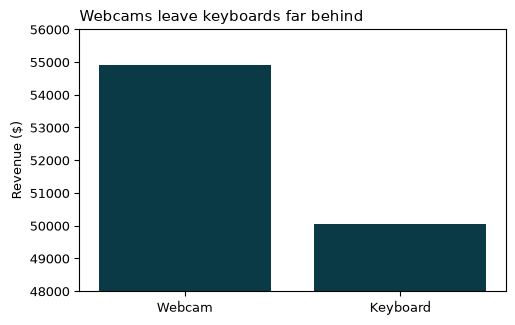

In [3]:
fig, ax = plt.subplots()
ax.bar(top2['product'], top2['revenue'])
ax.set_ylim(48000, 56000)
ax.set_title('Webcams leave keyboards far behind')
ax.set_ylabel('Revenue ($)')
plt.show()

In [4]:
webcam, keyboard = top2['revenue']
print(f'Real ratio: {webcam / keyboard:.2f}')
shown = (webcam - 48000) / (keyboard - 48000)
print(f'Ratio of bar heights: {shown:.2f}')

Real ratio: 1.10
Ratio of bar heights: 3.38


### The honest version

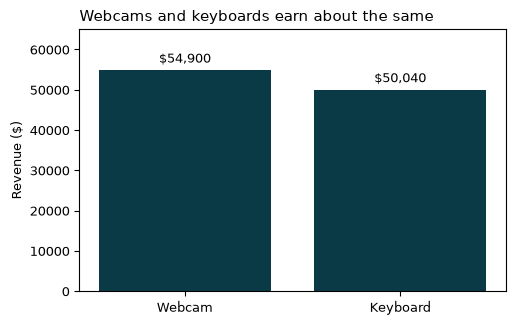

In [5]:
fig, ax = plt.subplots()
bars = ax.bar(top2['product'], top2['revenue'])
ax.bar_label(bars, fmt='${:,.0f}', padding=3)
ax.set_ylim(0, 65000)
ax.set_title('Webcams and keyboards earn about the same')
ax.set_ylabel('Revenue ($)')
plt.show()

### Line charts are different

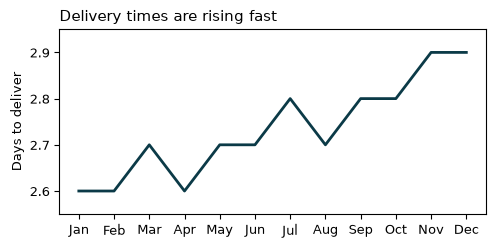

In [6]:
delivery = pd.read_csv('delivery_days.csv')

fig, ax = plt.subplots(figsize=(5.5, 2.4))
ax.plot(delivery['month'], delivery['delivery_days'])
ax.set_ylim(2.55, 2.95)
ax.set_title('Delivery times are rising fast')
ax.set_ylabel('Days to deliver')
plt.show()

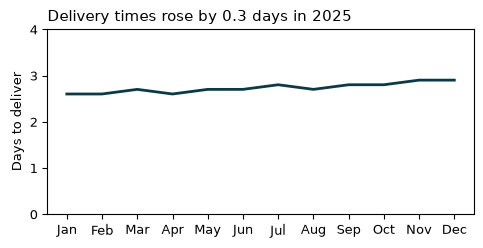

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 2.4))
ax.plot(delivery['month'], delivery['delivery_days'])
ax.set_ylim(0, 4)
ax.set_title('Delivery times rose by 0.3 days in 2025')
ax.set_ylabel('Days to deliver')
plt.show()

## 10.2 Misleading Scales

### Two y-axes

In [8]:
shop = pd.read_csv('monthly_shop.csv')
shop.head(3)

,month,revenue,orders,conversion
0,Jan,38200,470,0.0220
1,Feb,35900,452,0.0225
2,Mar,42800,547,0.0230


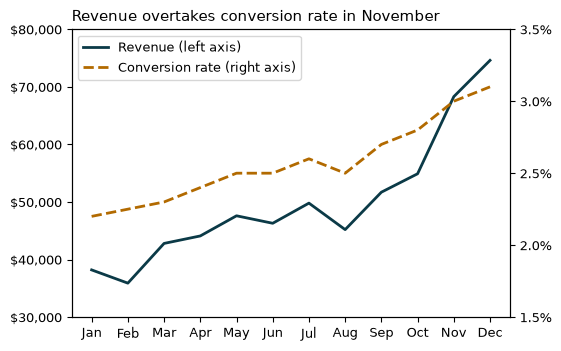

In [9]:
fig, ax = plt.subplots(layout='constrained')
ax2 = ax.twinx()
line1, = ax.plot(shop['month'], shop['revenue'],
                 label='Revenue (left axis)')
line2, = ax2.plot(shop['month'], shop['conversion'],
                  color='#b26a00', linestyle='--',
                  label='Conversion rate (right axis)')
ax.set_ylim(30000, 80000)
ax2.set_ylim(0.015, 0.035)
ax2.set_yticks([0.015, 0.02, 0.025, 0.03, 0.035])
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax2.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
ax.legend(handles=[line1, line2], loc='upper left')
ax.set_title('Revenue overtakes conversion rate in November')
plt.show()

In [10]:
measures = shop.set_index('month')[['revenue', 'conversion']]
indexed = measures / measures.iloc[0] * 100
indexed.round(1).head(3)

,revenue,conversion
month,,
Jan,100.0,100.0
Feb,94.0,102.3
Mar,112.0,104.5


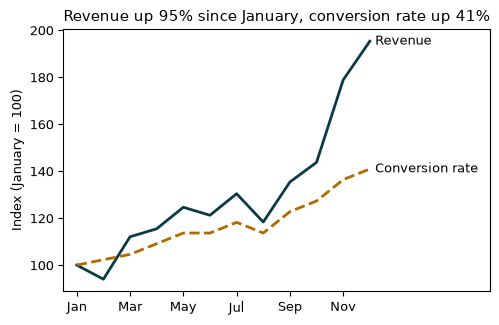

In [11]:
fig, ax = plt.subplots()
ax.plot(indexed.index, indexed['revenue'])
ax.plot(indexed.index, indexed['conversion'])
last = indexed.iloc[-1]
ax.set_xlim(-0.5, 15.5)
ax.set_xticks(range(0, 12, 2), indexed.index[::2])
ax.text(11.2, last['revenue'], 'Revenue', va='center')
ax.text(11.2, last['conversion'], 'Conversion rate', va='center')
ax.set_title(f"Revenue up {last['revenue'] - 100:.0f}% since January, "
             f"conversion rate up {last['conversion'] - 100:.0f}%")
ax.set_ylabel('Index (January = 100)')
plt.show()

### Log scales

In [12]:
pages = pd.read_csv('page_visits.csv')
round(pages['visits'].max() / pages['visits'].min())

1916

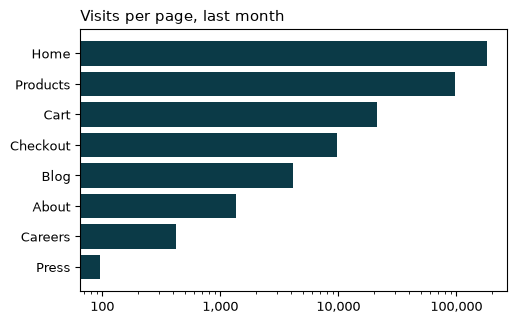

In [13]:
fig, ax = plt.subplots()
ax.barh(pages['page'], pages['visits'])
ax.invert_yaxis()
ax.set_xscale('log')
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set_title('Visits per page, last month')
plt.show()

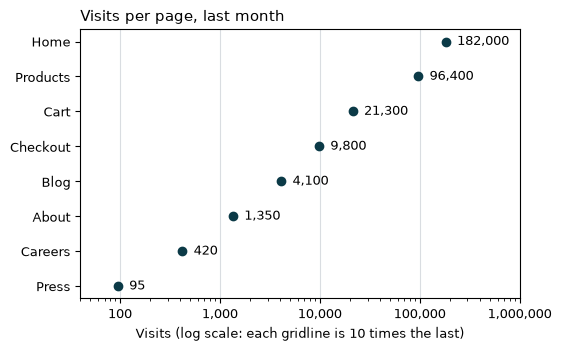

In [14]:
fig, ax = plt.subplots(layout='constrained')
ax.scatter(pages['visits'], pages['page'])
ax.invert_yaxis()
ax.set_xscale('log')
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set_xlim(40, 1000000)
ax.grid(axis='x')
for visits, page in zip(pages['visits'], pages['page']):
    ax.text(visits * 1.3, page, f'{visits:,}', va='center')
ax.set_title('Visits per page, last month')
ax.set_xlabel('Visits (log scale: each gridline is 10 times the last)')
plt.show()

## 10.3 Cherry-Picked Dates

In [15]:
sales = pd.read_csv('daily_sales.csv', parse_dates=['date'])
sales.head(3)

,date,revenue,orders,target
0,2025-01-06,1740,29,1900
1,2025-01-07,1560,24,1900
2,2025-01-08,1870,32,1900


In [16]:
window = sales[(sales['date'] >= '2025-04-05')
               & (sales['date'] <= '2025-04-10')]
start, end = window['revenue'].iloc[[0, -1]]
print(start, end, f'{end / start - 1:.0%}')

2750 2030 -26%


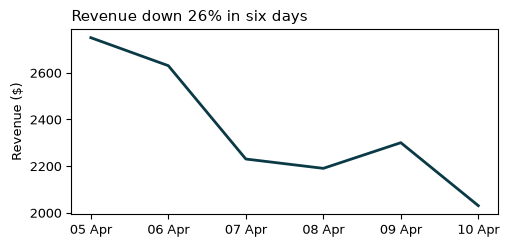

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 2.4))
ax.plot(window['date'], window['revenue'])
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_title('Revenue down 26% in six days')
ax.set_ylabel('Revenue ($)')
plt.show()

In [18]:
smooth = sales.set_index('date')['revenue'].rolling(7).mean()
smooth.round(0).iloc[[6, -1]]

date
2025-01-12    1824.0
2025-04-27    2463.0
Name: revenue, dtype: float64

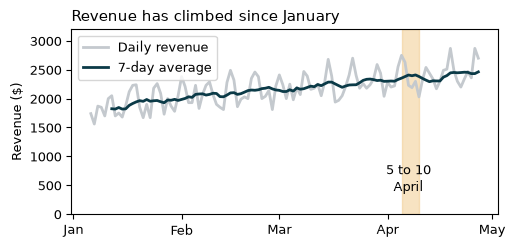

In [19]:
fig, ax = plt.subplots(figsize=(5.5, 2.4))
ax.plot(sales['date'], sales['revenue'], color='#c4c9ce',
        linestyle='-', label='Daily revenue')
ax.plot(smooth.index, smooth, color='#0b3a47', linestyle='-',
        label='7-day average')
ax.axvspan(pd.Timestamp('2025-04-05'), pd.Timestamp('2025-04-10'),
           color='#f0c987', alpha=0.5)
ax.text(pd.Timestamp('2025-04-07'), 400, '5 to 10\nApril',
        ha='center')
ax.set_ylim(0, 3200)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title('Revenue has climbed since January')
ax.set_ylabel('Revenue ($)')
ax.legend(loc='upper left')
plt.show()